# 电信客户流失分类小组实验

**A 数据工程师**：任务一 EDA、任务二预处理。**B 算法工程师**：任务三 A/B/C（GaussianNB、两种 SVM、MLP）。**C 集成与报告工程师（邓闽川）**：任务三 D/E、任务四和集成。运行前在仓库根目录准备课程提供的 `data/telco_churn.csv`，依赖和命令见同目录 README。

## 任务一 · 探索性分析（A）

输出标签计数和比例、缺失排查、四张特征关系图及相关性热力图。

原始规模： {'rows': 6014, 'columns': 21}
标签计数： {'No': 4424, 'Yes': 1589} 标签比例： {'No': 0.7357392316647264, 'Yes': 0.26426076833527357}
全空行： 0 缺标签： 1 重复行： 0
累计费用检查： {'original_dtype': 'str', 'blank_strings': 9, 'nonblank_conversion_failures': 0, 'numeric_missing_after_conversion': 10, 'numeric_missing_with_tenure_zero': 9, 'numeric_missing_with_tenure_nonzero': 1}
相关性最高的特征对： [{'feature_1': 'OnlineBackup_No internet service', 'feature_2': 'DeviceProtection_No internet service', 'correlation': 1.0}, {'feature_1': 'DeviceProtection_No internet service', 'feature_2': 'StreamingTV_No internet service', 'correlation': 1.0}, {'feature_1': 'OnlineSecurity_No internet service', 'feature_2': 'OnlineBackup_No internet service', 'correlation': 1.0}]


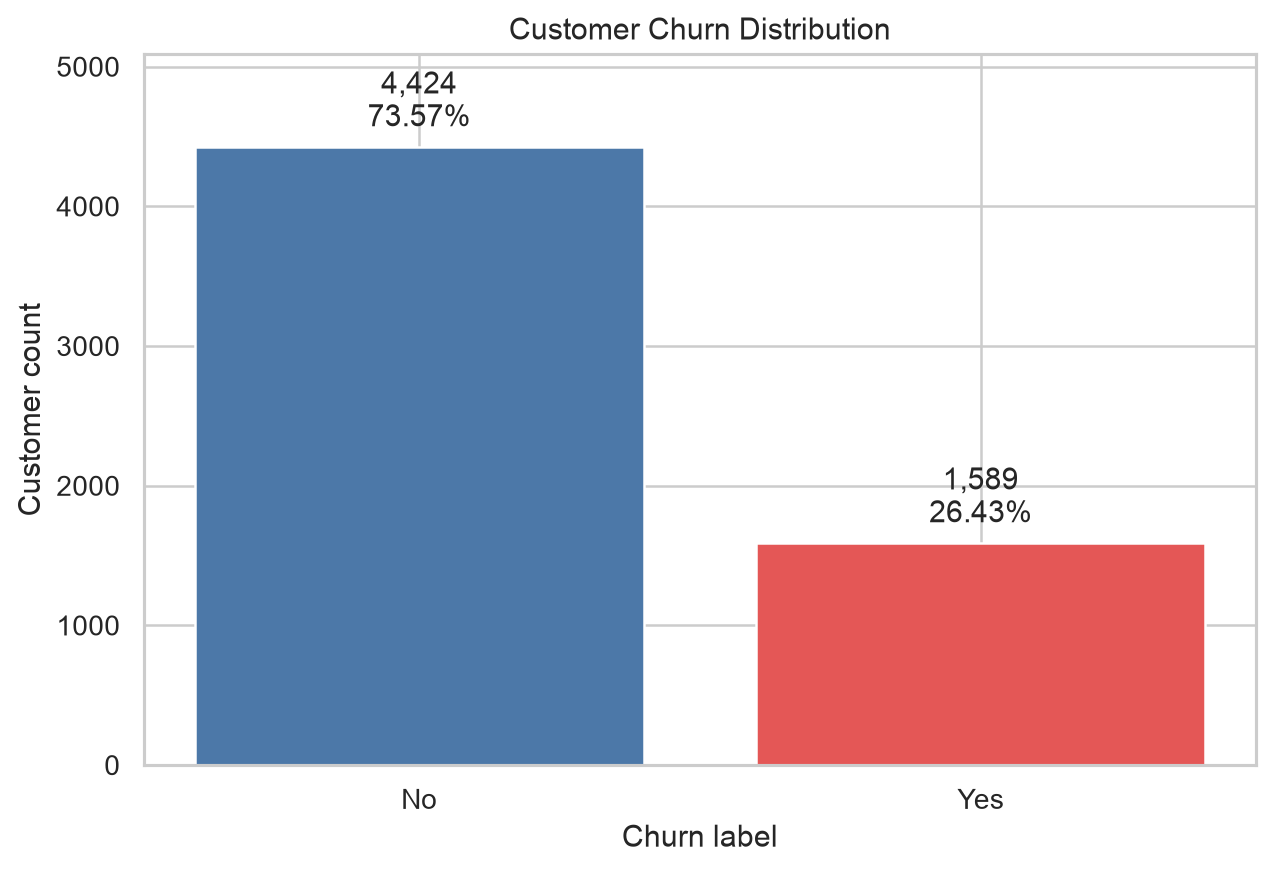

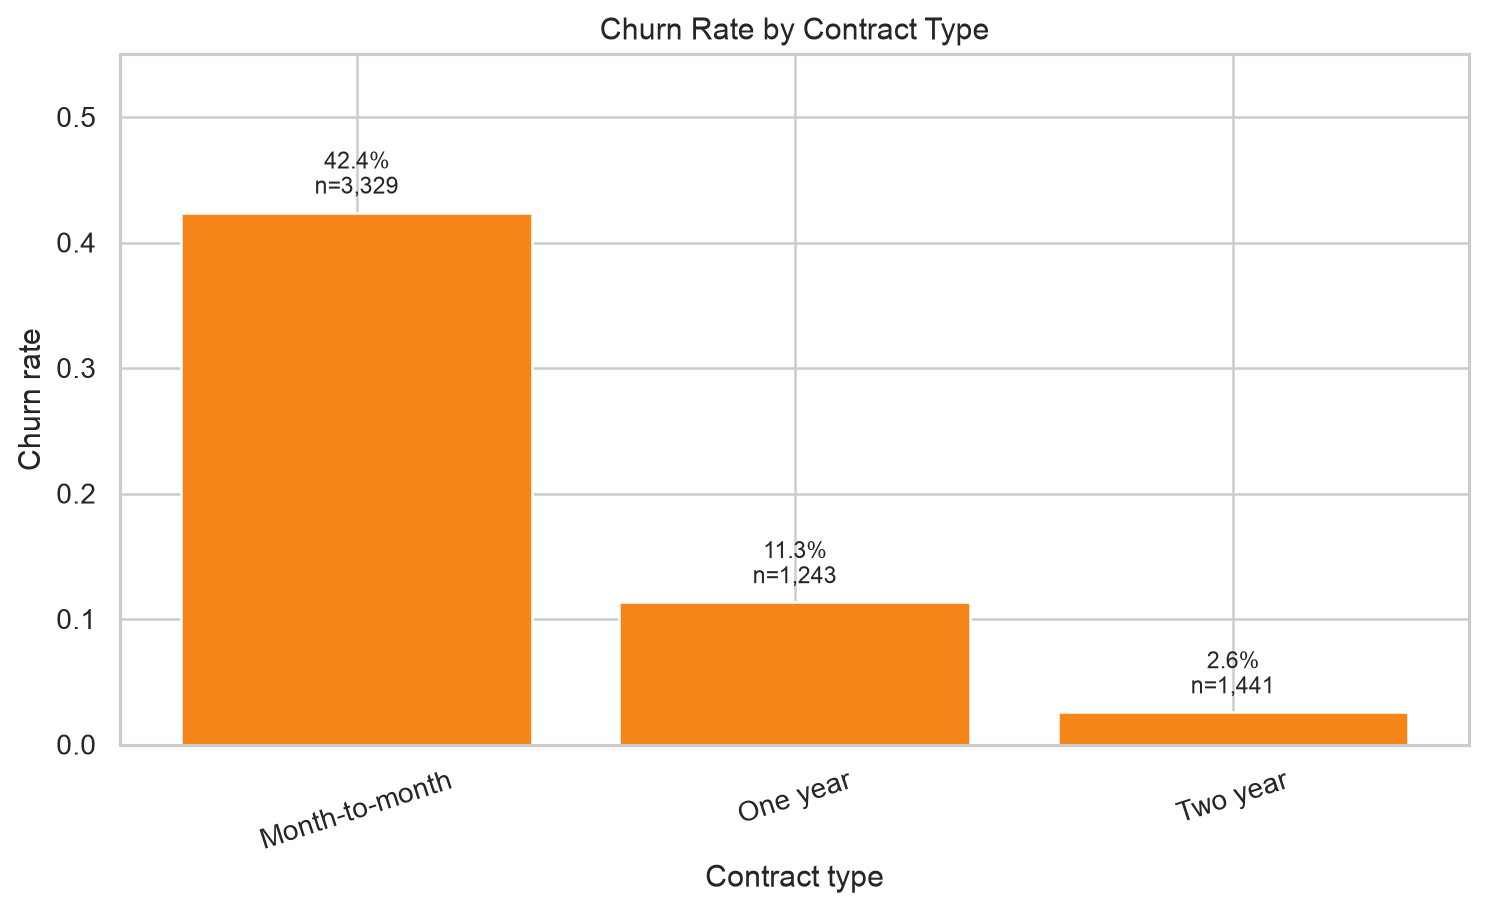

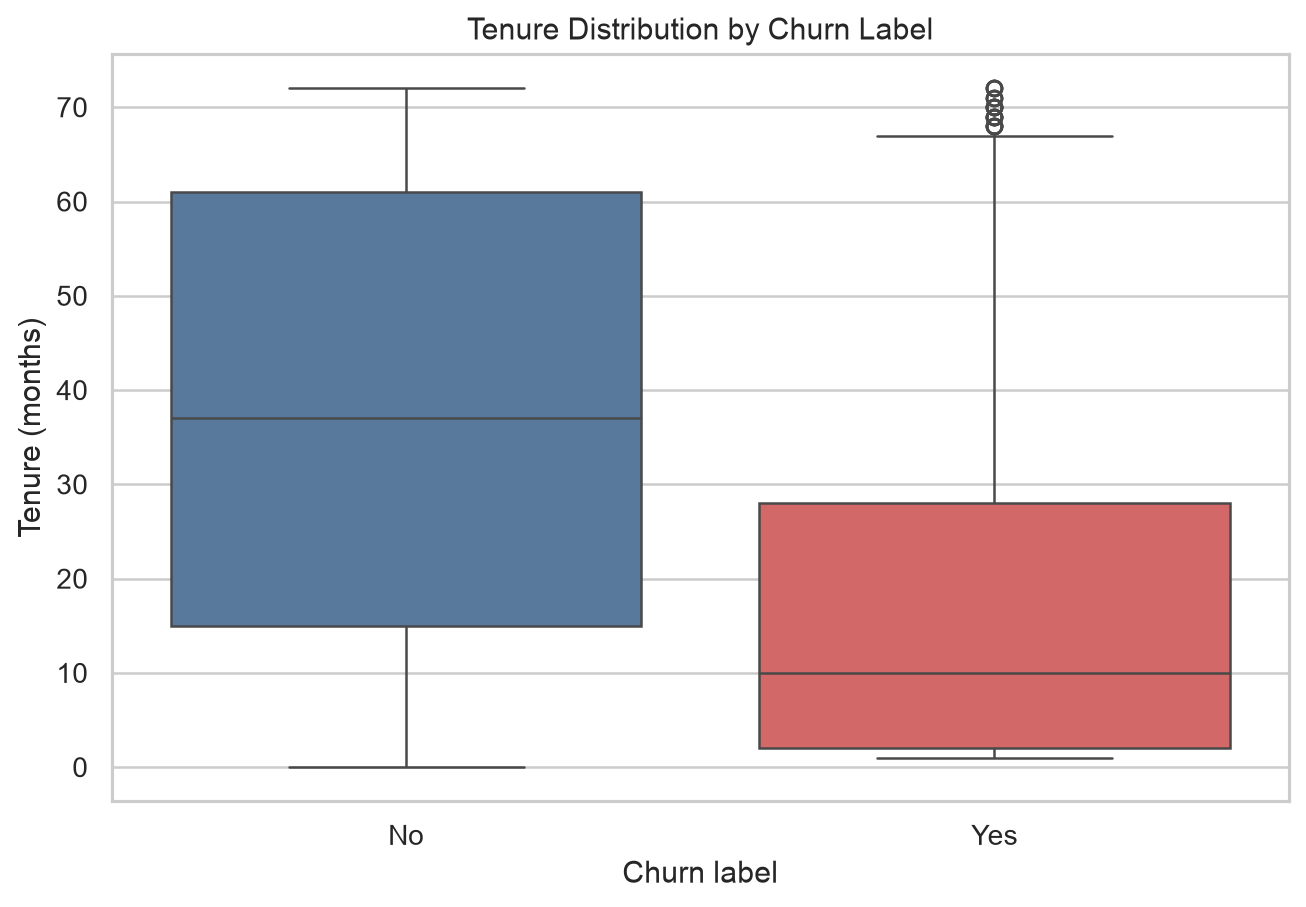

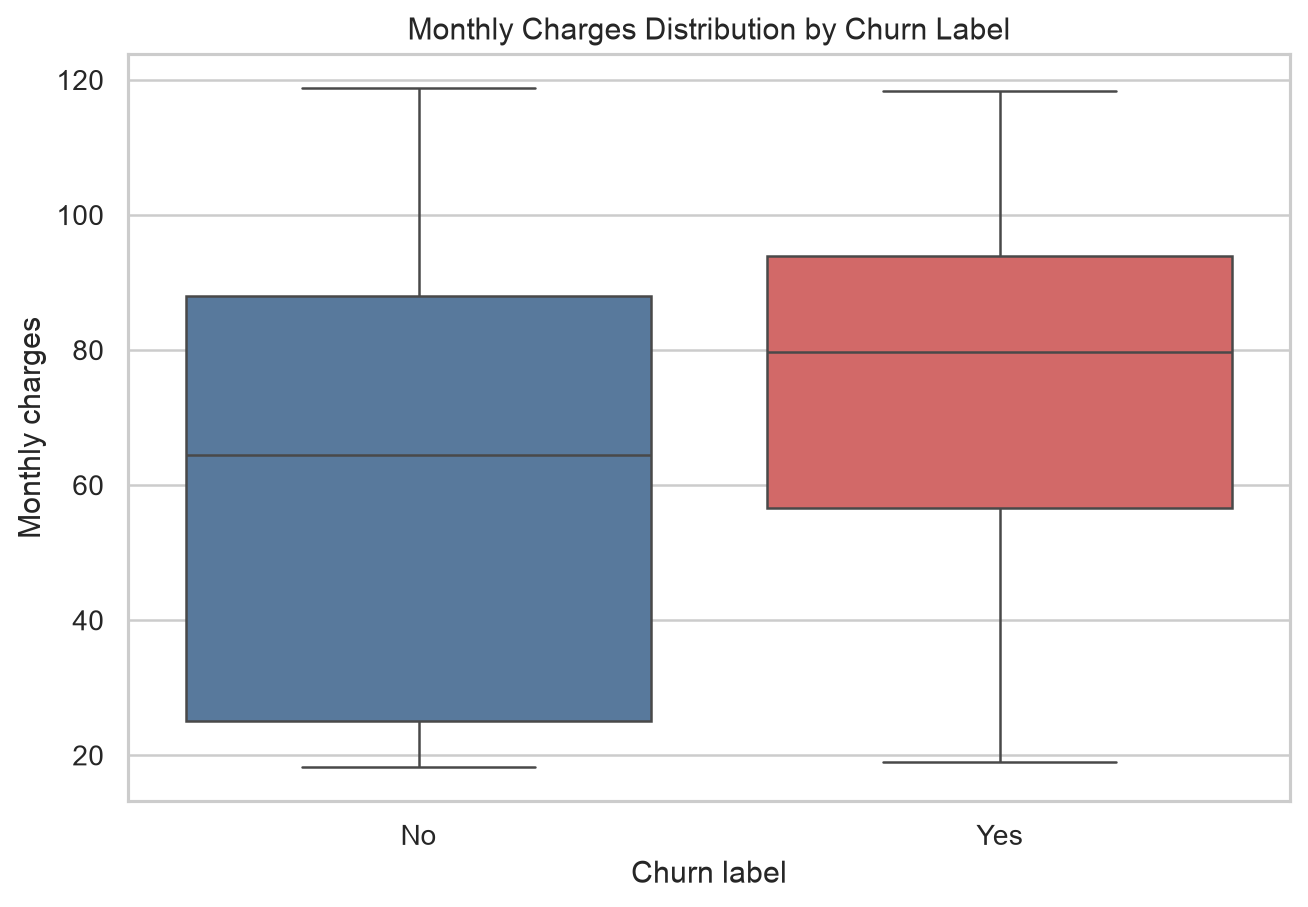

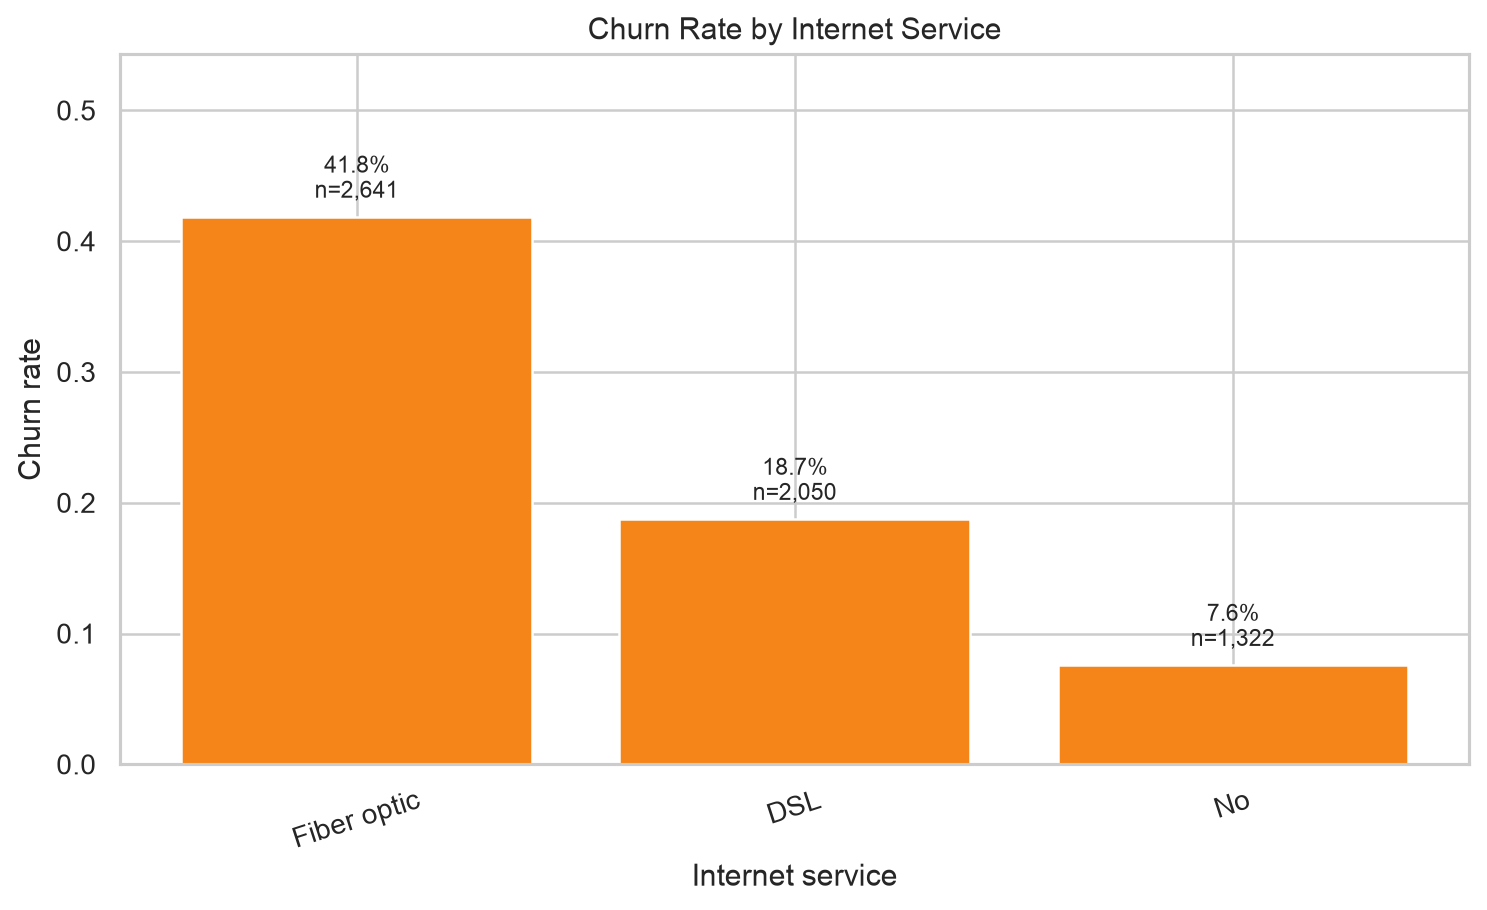

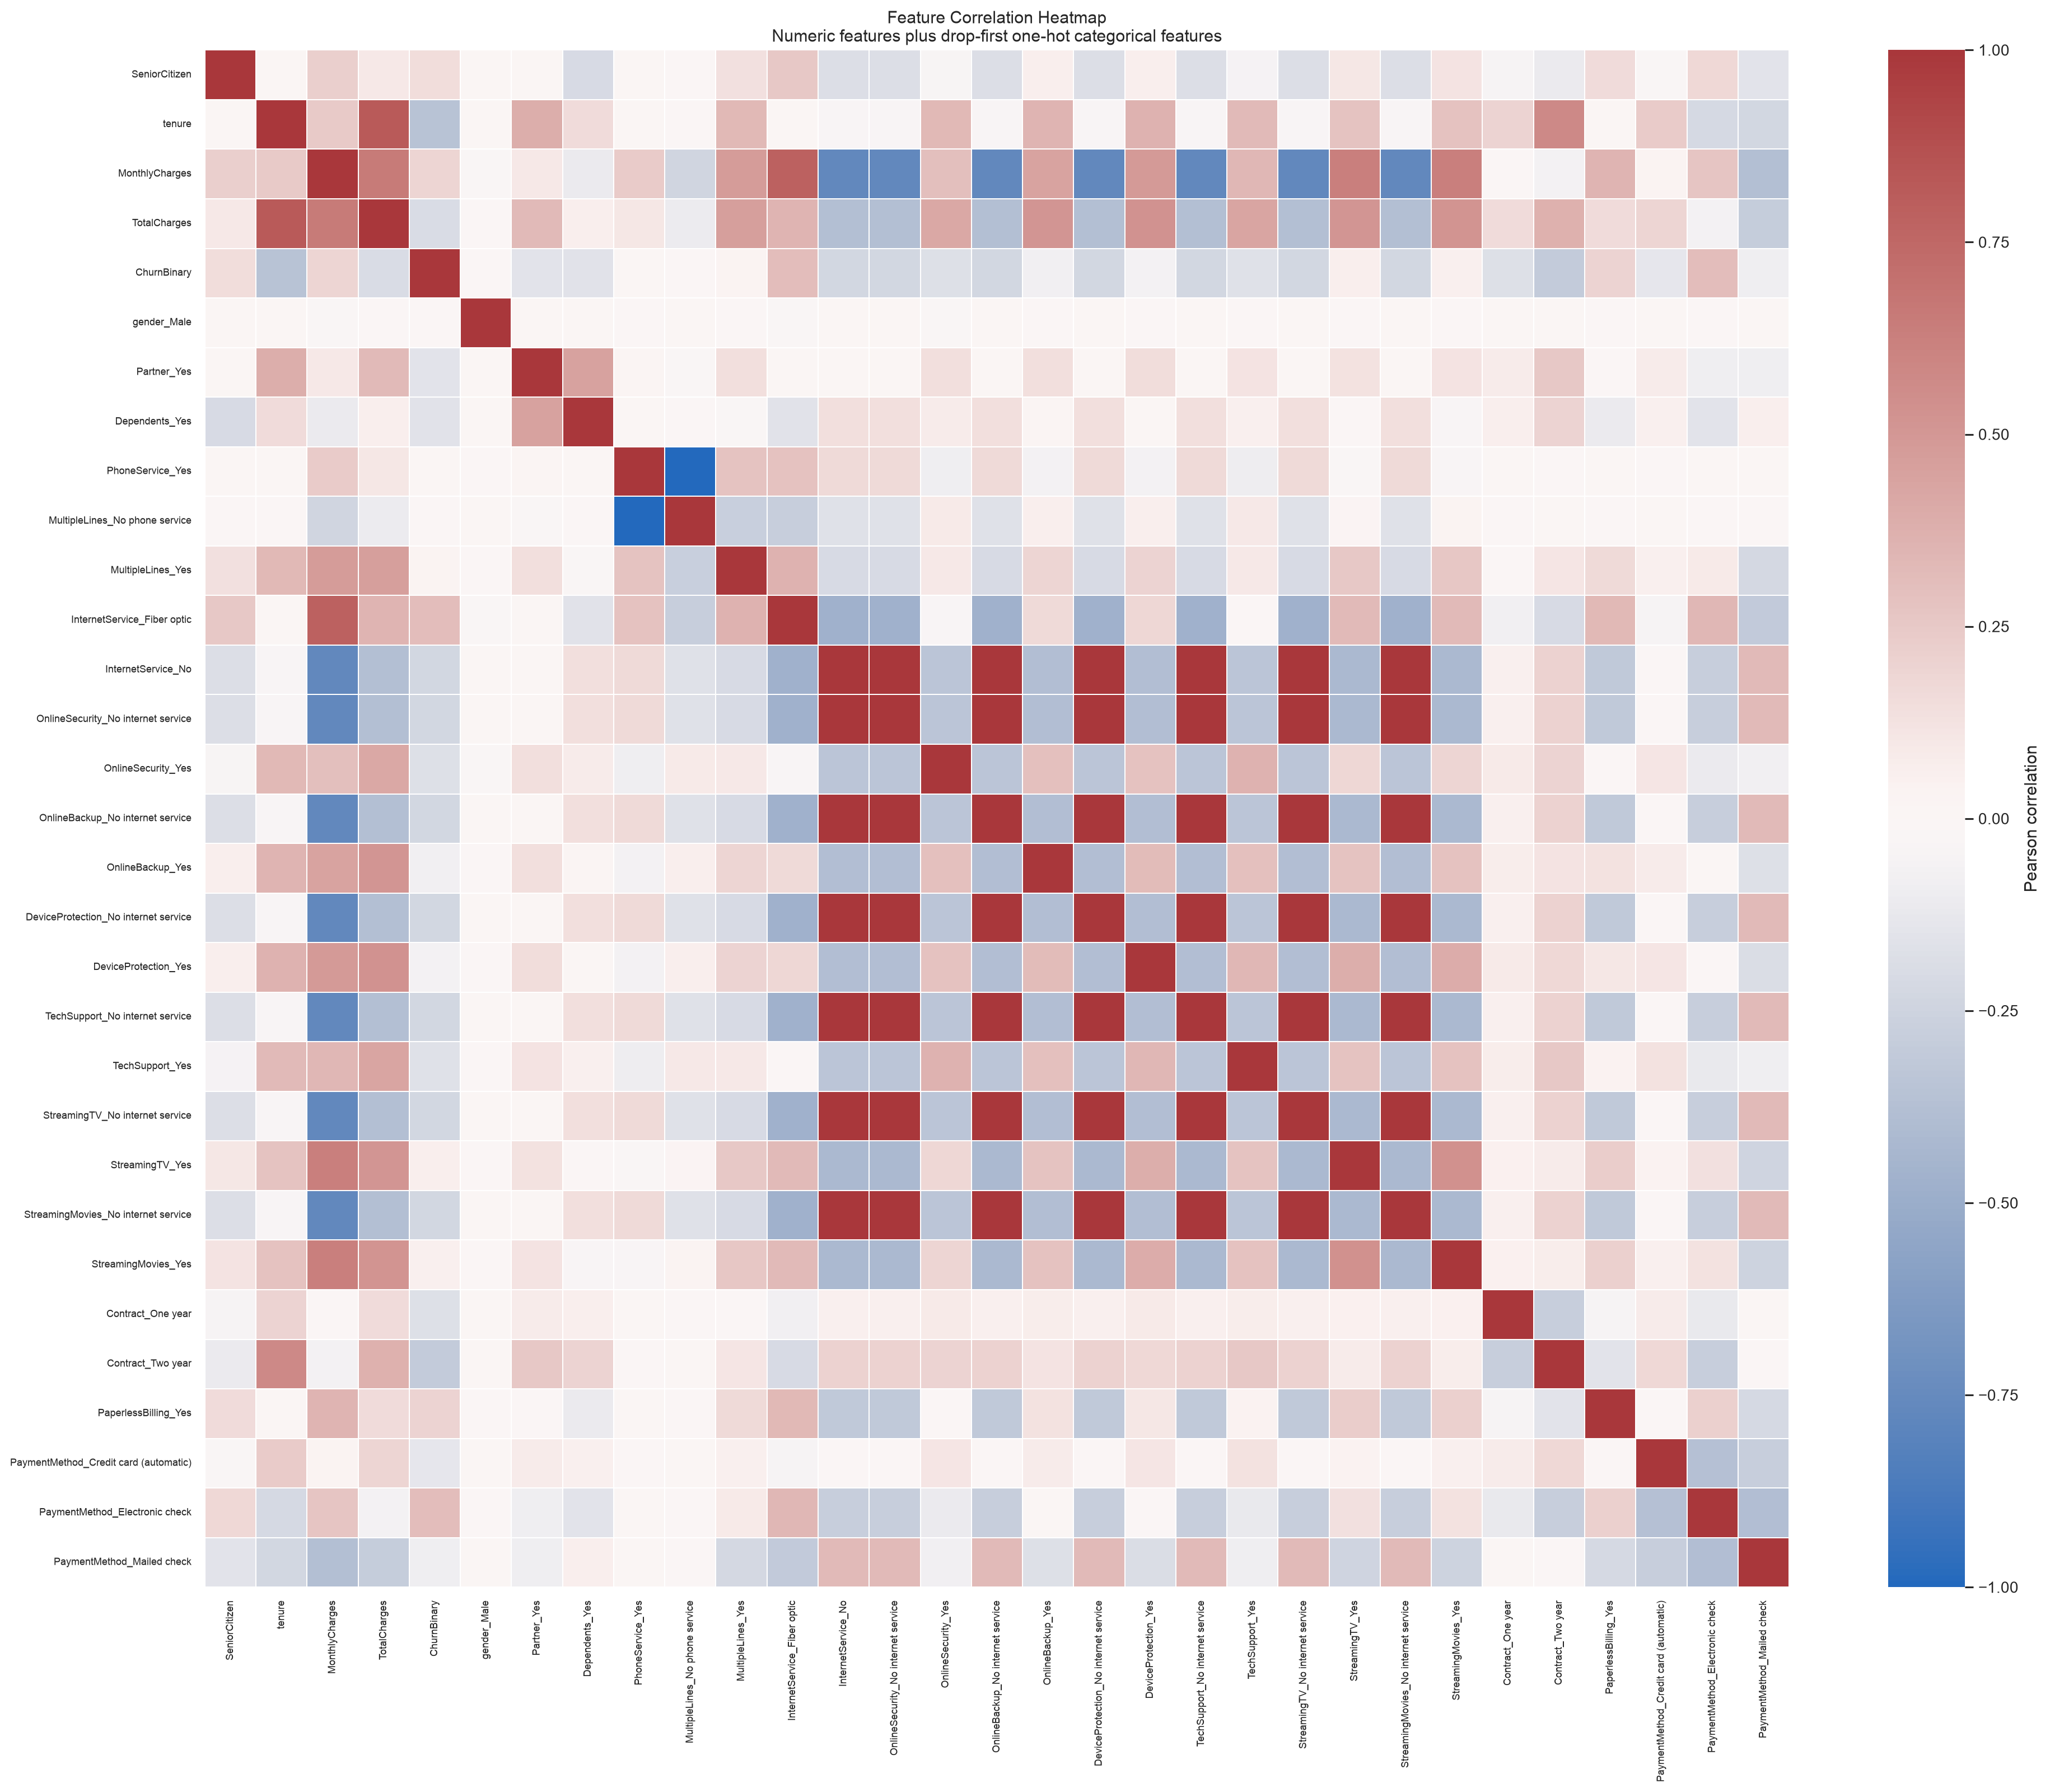

In [1]:
from IPython.display import Image, display
from tasks_de import DELIVERY_DIR, data_engineering
from src.data_engineering.eda import run_eda

eda = run_eda(output_dir=DELIVERY_DIR / 'outputs' / 'group_eda', force=True)
quality = eda.quality_summary
print('原始规模：', quality['shape'])
print('标签计数：', eda.churn_counts, '标签比例：', eda.churn_ratios)
print('全空行：', quality['all_empty_rows'], '缺标签：', quality['missing_target_rows'],
      '重复行：', quality['fully_duplicated_rows'])
print('累计费用检查：', quality['total_charges'])
print('相关性最高的特征对：', eda.top_correlations[:3])
for path in eda.output_paths:
    if path.suffix == '.png':
        display(Image(filename=path))

## 任务二 · 数据预处理（A）

保留分层的 80/20 划分；仅训练集拟合填补、编码类别和缩放，测试集仅做变换。

In [2]:
prepared = data_engineering.prepare_data()
print('清洗：', prepared.metadata['row_cleaning'], prepared.metadata['numeric_cleaning'])
print('划分：', prepared.metadata['split'])
print('未缩放矩阵形状：', prepared.X_train.shape, prepared.X_test.shape)
print('缩放：', prepared.metadata['scaling'])
assert prepared.X_train.index.intersection(prepared.X_test.index).empty
assert prepared.X_train.columns.equals(prepared.X_test.columns)

清洗： {'all_empty_rows_removed': 0, 'missing_target_rows_removed': 1, 'severely_incomplete_missing_target_rows': 1, 'fully_duplicated_rows_removed': 0} {'total_charges_nonblank_conversion_failures': 0, 'total_charges_tenure_zero_filled_with_zero': 9, 'total_charges_remaining_missing_before_split': 0}
划分： {'test_size': 0.2, 'random_state': 42, 'stratified': True, 'train_rows': 4810, 'test_rows': 1203, 'train_label_ratio': {'0': 0.7357588357588357, '1': 0.26424116424116423}, 'test_label_ratio': {'0': 0.7356608478802993, '1': 0.26433915211970077}}
未缩放矩阵形状： (4810, 30) (1203, 30)
缩放： {'method': 'StandardScaler', 'fit_on_training_only': True, 'n_samples_seen': 4810}


## 任务三 · 模型比武（B、C）

B：GaussianNB 使用未缩放数据，SVM/MLP 使用缩放数据。显示 B 的两种核支持向量数及 MLP 损失曲线。C：全不流失基线、决策树深度扫描和随机森林。沿用同一测试集，以标签 1 为流失。

/Users/Admin/Desktop/研究生学校相关报告/数据分析/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/Users/Admin/Desktop/研究生学校相关报告/数据分析/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/Users/Admin/Desktop/研究生学校相关报告/数据分析/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/Users/Admin/Desktop/研究生学校相关报告/数据分析/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/Users/Admin/Desktop/研究生学校相关报告/数据分析/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/Users/Admin/Desktop/研究生学校相关报告/数据分析/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


... (3 outputs left out)

/Users/Admin/Desktop/研究生学校相关报告/数据分析/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/Users/Admin/Desktop/研究生学校相关报告/数据分析/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/Users/Admin/Desktop/研究生学校相关报告/数据分析/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


B 留出集结果来源： 交付预测（已校验）
      模型    准确率    灵敏度    特异度    AUC
    随机森林 0.8071 0.5377 0.9040 0.8284
 SVM-线性核 0.7938 0.5472 0.8825 0.8199
     决策树 0.7872 0.4937 0.8927 0.8141
   朴素贝叶斯 0.6492 0.8679 0.5706 0.8067
SVM-RBF核 0.7955 0.5000 0.9017 0.8029
     MLP 0.7598 0.5503 0.8350 0.7859
  全不流失基线 0.7357 0.0000 1.0000 0.5000
B 原始实验：线性 SVM 支持向量 2183 个；RBF SVM 2298 个；MLP 迭代 298 轮。


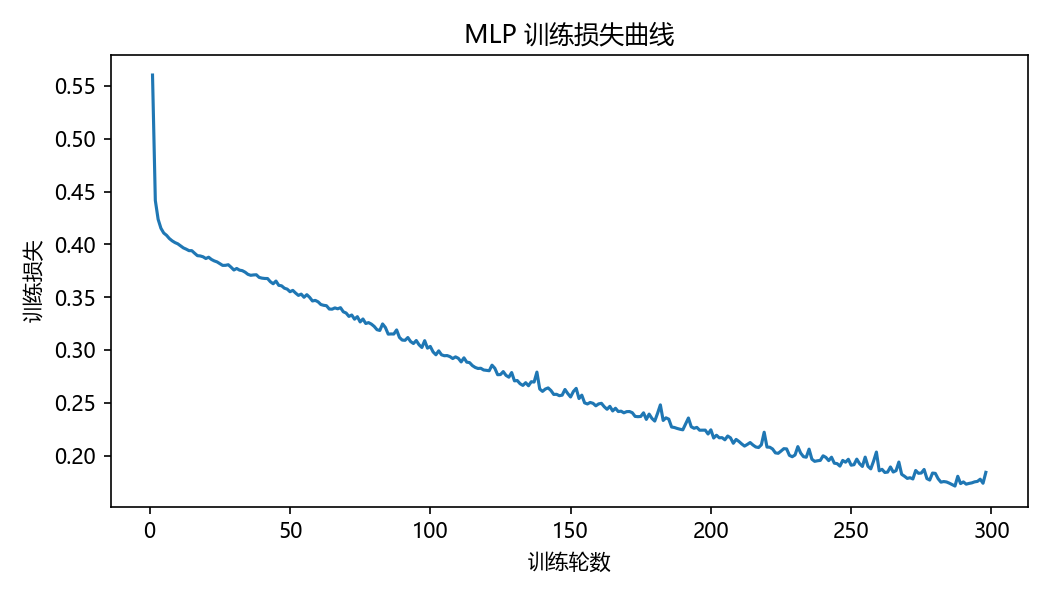

,max_depth,train_auc_mean,validation_auc_mean,validation_auc_std,selected
3,5,0.8544,0.8159,0.0107,True


feature
TotalCharges      0.1939
MonthlyCharges    0.1696
tenure            0.1622
Name: importance, dtype: float64

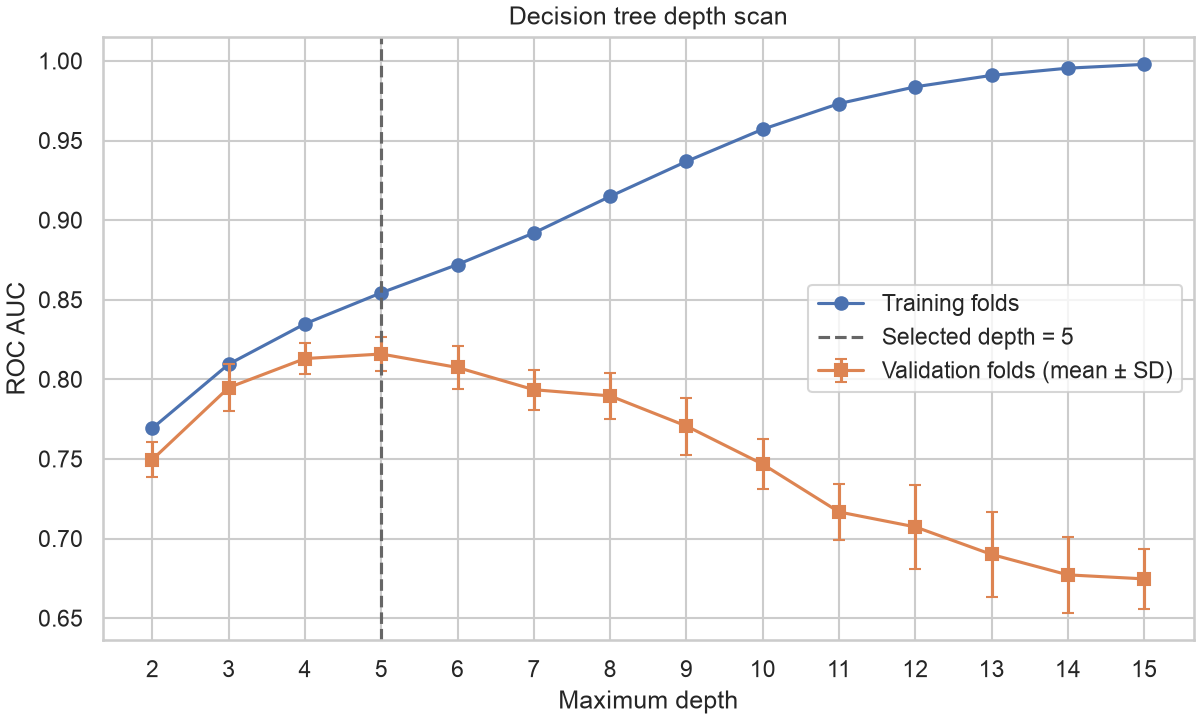

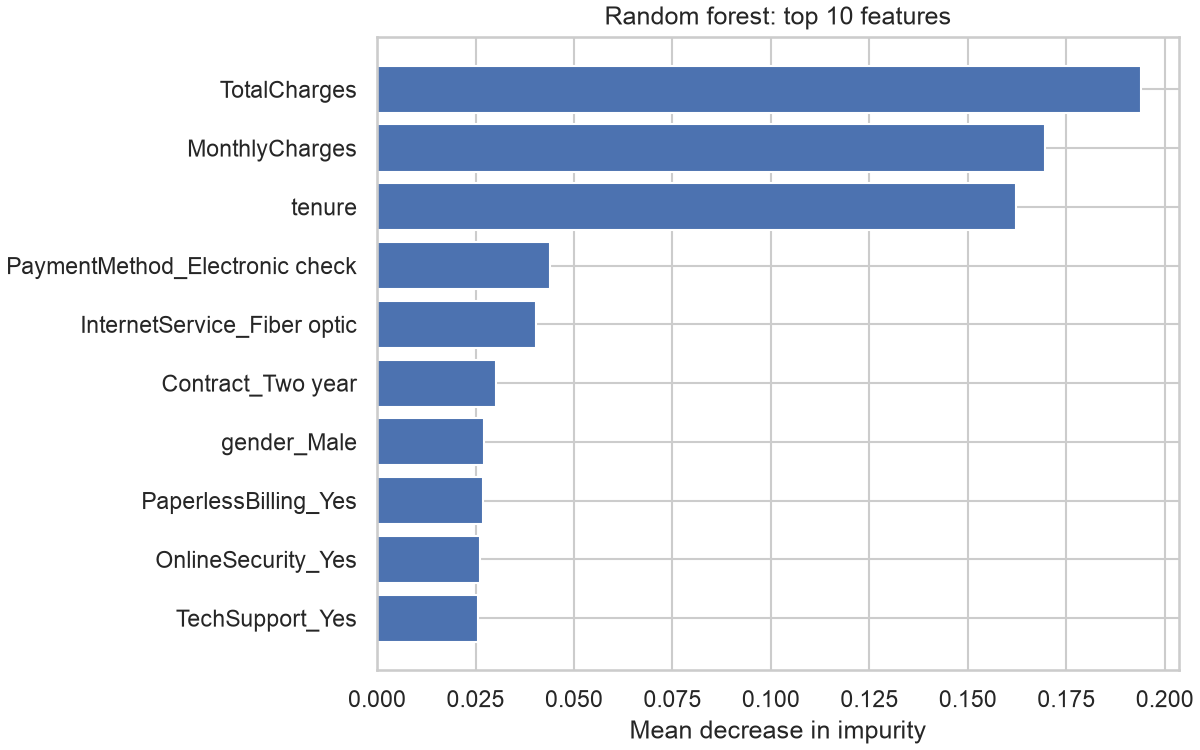

In [3]:
from task_four import B_OUTPUT_DIR, OUTPUT_DIR, run_evaluation
from tasks_de import OUTPUT_DIR as DE_OUTPUT_DIR, run_experiment

_, _, depth_scan, feature_importance = run_experiment()
has_b_delivery = B_OUTPUT_DIR.is_dir()
scorecard, cv, comparison, changes, missing = run_evaluation(
    b_source=B_OUTPUT_DIR if has_b_delivery else None, refit_b=True
)
assert not missing
print('B 留出集结果来源：', '交付预测（已校验）' if has_b_delivery else '按 B 配置在同一划分重训')
labels = {'model': '模型', 'acc': '准确率', 'sens': '灵敏度', 'spec': '特异度', 'auc': 'AUC'}
print(scorecard[list(labels)].rename(columns=labels).to_string(index=False, float_format='{:.4f}'.format))
print('B 原始实验：线性 SVM 支持向量 2183 个；RBF SVM 2298 个；MLP 迭代 298 轮。')
display(Image(filename=DELIVERY_DIR / 'outputs' / 'group_b' / 'fig04_mlp_loss.png'))
display(depth_scan.loc[depth_scan['selected']].round(4), feature_importance.head(3).round(4))
display(Image(filename=DE_OUTPUT_DIR / 'fig05_tree_depth.png'))
display(Image(filename=DE_OUTPUT_DIR / 'fig06_rf_importance.png'))

## 任务四 · 统一评估与不平衡处理（C）

五类模型 ROC；SVM 两种核单列。分层五折验证只在 A 的训练集内进行，SVM/MLP 的缩放在每折的 Pipeline 内拟合；各外折内重新选择决策树深度。随机森林和 RBF SVM 分别在本地成对重训，唯一改动是 `class_weight`。成绩单按 AUC，而非准确率排序。

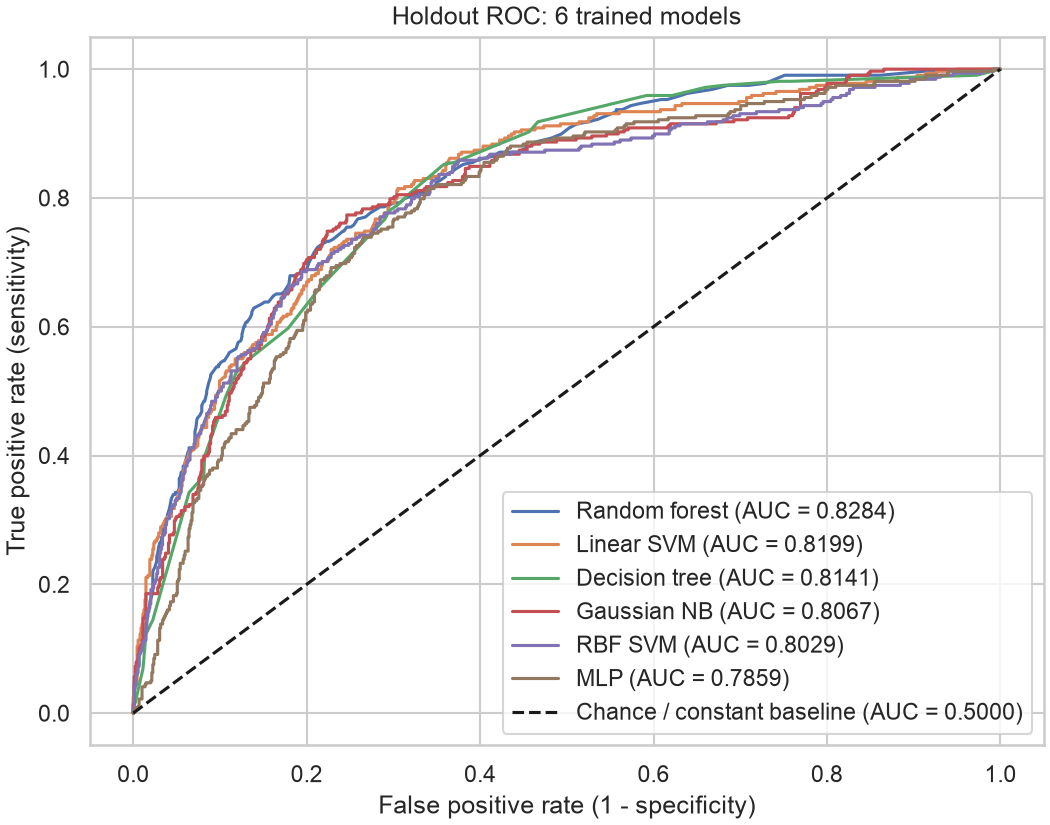

,model,fold_1,fold_2,fold_3,fold_4,fold_5,mean_auc,std_auc
3,SVM-线性核,0.8342,0.8463,0.8219,0.8363,0.8286,0.8334,0.0081
2,朴素贝叶斯,0.8134,0.8424,0.8215,0.8229,0.8138,0.8228,0.0105
1,随机森林,0.8024,0.8284,0.8153,0.8501,0.8070,0.8206,0.0172
0,决策树,0.8184,0.8367,0.7996,0.8306,0.8124,0.8195,0.0132
4,SVM-RBF核,0.7945,0.8271,0.7801,0.8179,0.7895,0.8018,0.0178
5,MLP,0.7335,0.7892,0.7463,0.7727,0.7698,0.7623,0.0198


,model,setting,acc,sens,spec,auc,tn,fp,fn,tp
0,随机森林,默认,0.8071,0.5377,0.9040,0.8284,800,85,147,171
1,随机森林,加权,0.7772,0.6635,0.8181,0.8288,724,161,107,211
2,SVM-RBF核,默认,0.7955,0.5000,0.9017,0.8029,798,87,159,159
3,SVM-RBF核,加权,0.7298,0.7484,0.7232,0.8060,640,245,80,238


,model,delta_sensitivity_pp,delta_specificity_pp,delta_tp,delta_fp
0,随机森林,12.58,-8.59,40,76
1,SVM-RBF核,24.84,-17.85,79,158


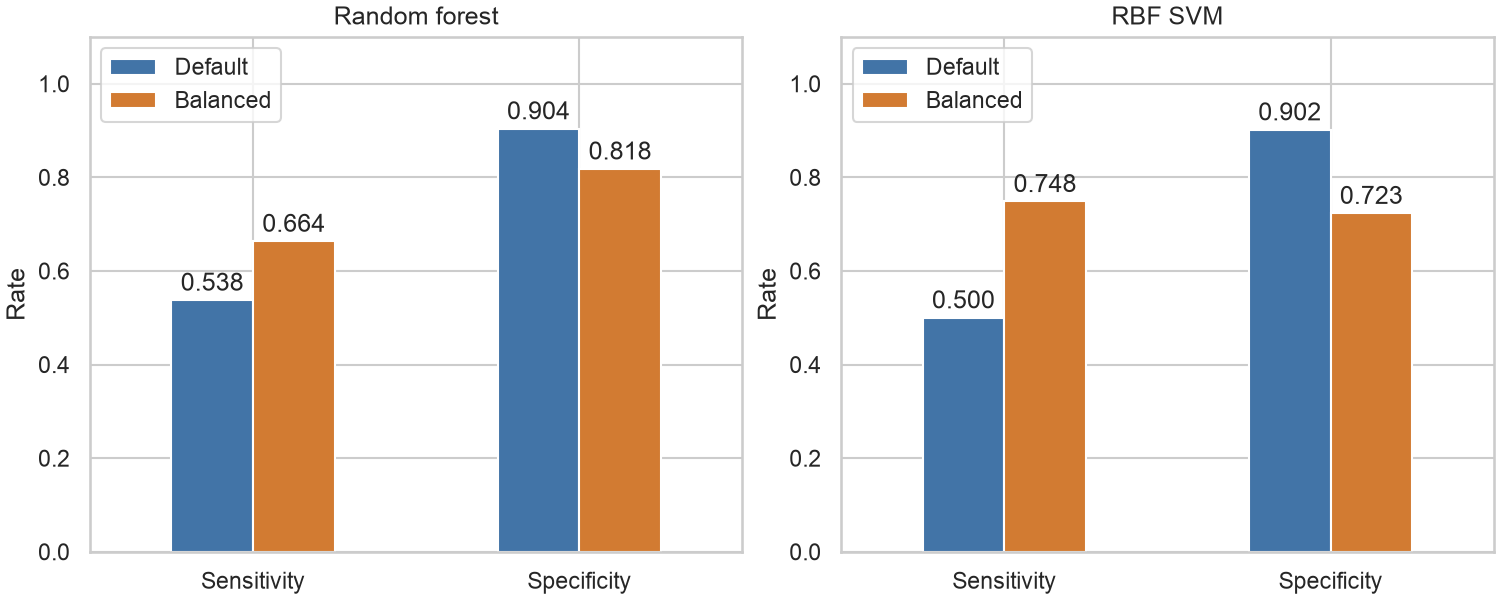

留出集 AUC 第一： 随机森林
五折平均 AUC 第一： SVM-线性核
随机森林 加权后：识别流失 +40 人，误报 +76 人。
SVM-RBF核 加权后：识别流失 +79 人，误报 +158 人。


In [4]:
display(Image(filename=OUTPUT_DIR / 'fig07_roc_all.png'))
display(cv.round(4), comparison.round(4), changes.round(2))
display(Image(filename=OUTPUT_DIR / 'fig08_imbalance.png'))
print('留出集 AUC 第一：', scorecard.iloc[0]['model'])
print('五折平均 AUC 第一：', cv.iloc[0]['model'])
for row in changes.itertuples(index=False):
    print(f'{row.model} 加权后：识别流失 {row.delta_tp:+d} 人，误报 {row.delta_fp:+d} 人。')

## 小组报告

参见同目录 [实验报告](实验报告.md)，第 5 节记录全组 AI 使用情况，第 6 节记录分工和技术走查。